Cloning into 'ie-healthcare-access-dataviz'...
remote: Enumerating objects: 99, done.
remote: Counting objects: 100% (99/99), done.
remote: Compressing objects: 100% (71/71), done.
remote: Total 99 (delta 41), reused 70 (delta 21), pack-reused 0 (from 0)
Receiving objects: 100% (99/99), 2.96 MiB | 22.29 MiB/s, done.
Resolving deltas: 100% (41/41), done.
/content/ie-healthcare-access-dataviz/ie-healthcare-access-dataviz/ie-healthcare-access-dataviz/ie-healthcare-access-dataviz/ie-healthcare-access-dataviz/ie-healthcare-access-dataviz/ie-healthcare-access-dataviz
unmet_need_by_reason_v1_2026-11-11.csv	waiting_list_national_v1_2026-11-11.csv


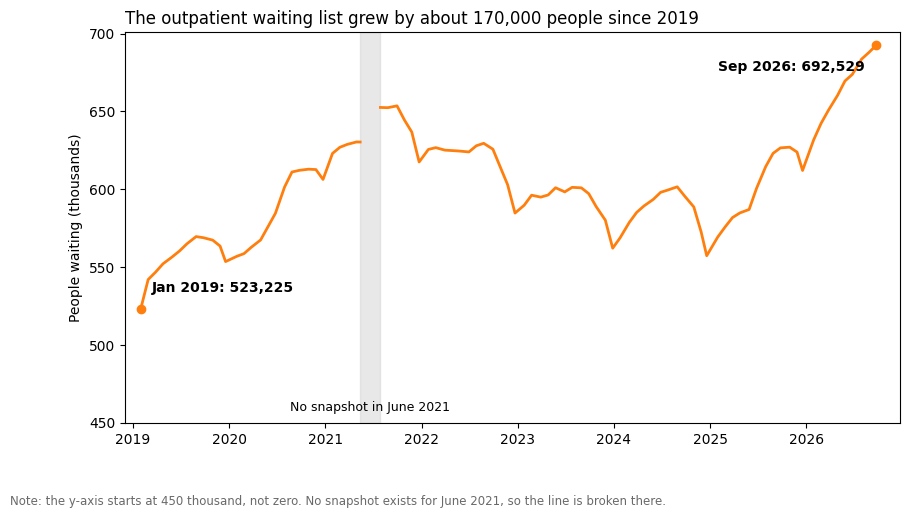

chart2b_ranking_2025.png  chart3a_waiting_list_over_time.png
chart2_ireland_vs_eu.png


In [ ]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

PREPARED = Path("data/prepared")
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)

ORANGE = "#eb6834"  # waiting
BLUE = "#2a78d6"    # cost
GREY = "#898781"    # EU average and background

unmet = pd.read_csv(PREPARED / "unmet_need_by_reason_v1_2026-11-11.csv")
waiting = pd.read_csv(PREPARED / "waiting_list_national_v1_2026-11-11.csv", parse_dates=["snapshot"])

total = waiting.groupby("snapshot")["people"].sum() / 1000
total.head()
waiting["snapshot"] = pd.to_datetime(waiting["snapshot"])

before = total[total.index < "2021-06-01"]
after  = total[total.index >= "2021-06-01"]

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(before.index, before.values, color="tab:orange", linewidth=2)
ax.plot(after.index, after.values, color="tab:orange", linewidth=2)

ax.axvspan(pd.Timestamp("2021-05-13"), pd.Timestamp("2021-07-29"), color="lightgrey", alpha=0.5)
ax.text(pd.Timestamp("2021-06-20"), 0.03, "No snapshot in June 2021",
        transform=ax.get_xaxis_transform(), ha="center", fontsize=9)

# first and last points
first_x, first_y = total.index[0], total.iloc[0]
last_x,  last_y  = total.index[-1], total.iloc[-1]
ax.scatter([first_x, last_x], [first_y, last_y], color="tab:orange", zorder=3)
ax.annotate(f"Jan 2019: {first_y*1000:,.0f}", (first_x, first_y),
            xytext=(8, 12), textcoords="offset points", fontsize=10, fontweight="bold")
ax.annotate(f"Sep 2026: {last_y*1000:,.0f}", (last_x, last_y),
            xytext=(-8, -18), textcoords="offset points", ha="right", fontsize=10, fontweight="bold")

# axes
ax.set_ylim(bottom=450)
ax.set_xlim(first_x - pd.Timedelta(days=60), last_x + pd.Timedelta(days=90))
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_ylabel("People waiting (thousands)")
ax.set_title("The outpatient waiting list grew by about 170,000 people since 2019", loc="left")

fig.subplots_adjust(bottom=0.17)
fig.text(0.01, 0.02, "Note: the y-axis starts at 450 thousand, not zero. No snapshot exists for June 2021, so the line is broken there.",
         fontsize=8.5, color="dimgrey")
plt.show()

import os
os.makedirs("figures", exist_ok=True)
fig.savefig("figures/chart3a_waiting_list_over_time.png", dpi=200, bbox_inches="tight")


**Why this chart type:** A line, because the chart shows 92 monthly snapshots and the story is the movement of one number, the total, over time. Bars would be too crowded at this size. A stacked area would split the total into four bands, and only the bottom layer sits on a flat baseline, so the shape of the total would be harder to read. The y-axis starts at 450 thousand, not zero, because the list is large and fairly flat from zero, and this is stated in the note under the chart. The line is broken at June 2021 because no snapshot exists for that month, and no value was estimated.

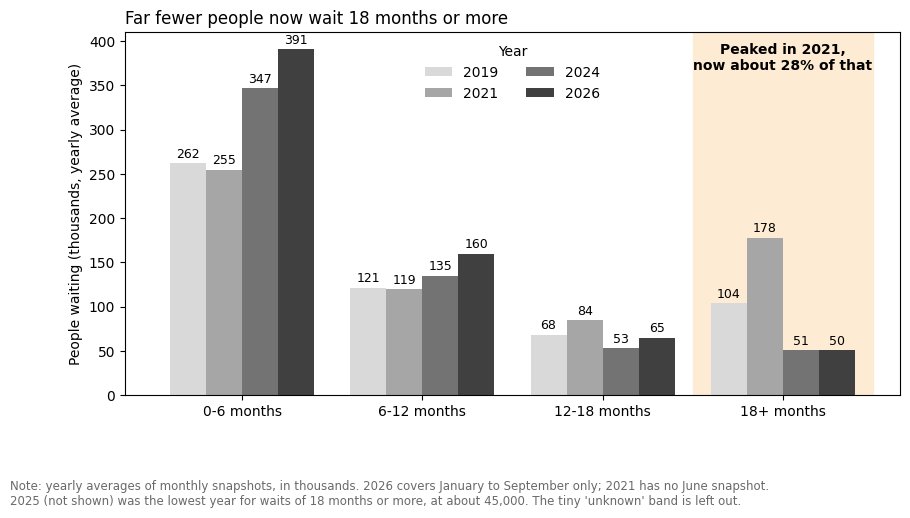

chart2b_ranking_2025.png  chart3a_waiting_list_over_time.png
chart2_ireland_vs_eu.png  chart3b_how_long_people_wait.png


In [9]:
bands = ["0-6 months", "6-12 months", "12-18 months", "18+ months"]
waiting["year"] = waiting["snapshot"].dt.year
monthly = waiting.groupby(["year", "snapshot", "band"])["people"].sum()
yearly = monthly.groupby(["year", "band"]).mean().unstack()[bands] / 1000
yearly = yearly.loc[[2019, 2021, 2024, 2026]]
yearly.round(1)

greys = ["#D9D9D9", "#A6A6A6", "#737373", "#404040"]   # light (2019) to dark (2026)

fig, ax = plt.subplots(figsize=(10, 5.5))
yearly.T.plot(kind="bar", ax=ax, color=greys, width=0.8)

# value on top of every bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=2, fontsize=9)

# highlight the 18+ months group (the 4th group, position 3)
ax.axvspan(2.5, 3.5, color="#FDEBD3", zorder=0)
ax.set_axisbelow(True)
ax.text(3, 0.97, "Peaked in 2021,\nnow about 28% of that",
        transform=ax.get_xaxis_transform(), ha="center", va="top",
        fontsize=10, fontweight="bold")

ax.set_ylim(bottom=0)
ax.set_xlabel("")
ax.set_ylabel("People waiting (thousands, yearly average)")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Year", frameon=False, ncol=2, loc="upper center")
ax.set_title("Far fewer people now wait 18 months or more", loc="left")

fig.subplots_adjust(bottom=0.22)
fig.text(0.01, 0.02,
         "Note: yearly averages of monthly snapshots, in thousands. 2026 covers January to September only; 2021 has no June snapshot.\n"
         "2025 (not shown) was the lowest year for waits of 18 months or more, at about 45,000. The tiny 'unknown' band is left out.",
         fontsize=8.5, color="dimgrey")

import os
os.makedirs("figures", exist_ok=True)
fig.savefig("figures/chart3b_how_long_people_wait.png", dpi=200, bbox_inches="tight")
plt.show()


**Why this chart type:** Grouped bars, because the question is how each waiting-time band changed across four years, and bars compare values side by side from a zero baseline. A stacked area chart would pile the four bands on top of each other, so only the bottom layer would be easy to compare, and the 18+ group, which is the story, would be hardest to read. The four greys run from light (2019) to dark (2026) so the years read in order, and blue is avoided because blue means cost in the other charts.

**Chart 3a commentary:** The national outpatient waiting list grew from 523,225 people in January 2019 to 692,529 in September 2026, an increase of about 170,000. It rose through 2020 and 2021, peaking at about 653,000 in September 2021. It then fell to about 562,000 by December 2023, and has risen again, from about 557,000 in December 2024 to its highest level in this data. There is no snapshot for June 2021, so the line is broken there rather than estimated.

**Chart 3b commentary:** People waiting 18 months or more averaged about 178,000 in 2021, then fell to about 50,000 in 2024 and 2026, which is about 28% of the 2021 level. Shorter waits grew over the same period: the 0-6 month group went from about 262,000 in 2019 to about 391,000 in 2026, and the 6-12 month group reached its highest average in 2026. The 18+ group has stopped falling: 2025 was the low at about 45,000, and 2026 is slightly higher. 2026 only covers January to September. [Optional: add one hedged, sourced sentence on why 2021 was high, for example the pause in elective care during 2020.]